# 01. Análise Exploratória de Dados (EDA) e Validação Estatística
### Previsão de Séries Temporais Financeiras (*Jane Street Real-Time Market Data*)

Este notebook fundamenta empiricamente cada decisão técnica do pipeline **Core** e dos **Testes Comparativos**:

1. **Estabilidade Temporal (`date_id >= 700`):** Verificação da contagem diária de `time_id`s e ativos (`symbol_id`) ao longo de todo o histórico.
2. **Distribuição do Alvo e Pesos:** Estatísticas descritivas (assimetria, curtose e *outliers*) de `responder_6` e proporção de amostras com `weight == 0`.
3. **Correlação entre Alvos:** Mapa de calor de `responder_0` a `responder_8` para embasar o experimento *Multi-Task* (`responder_6 + 7 + 8`).
4. **Radiografia de Valores Ausentes (`NaN`):** Percentual de falhas por *feature* e evolução temporal para embasar a ablação `NaN = 0` vs. `ffill`.
5. **Colinearidade e Sinal Linear:** Correlação das 79 *features* com `responder_6` e redundância entre atributos, justificando a poda para Top 30–50 via Random Forest/XGBoost.
6. **Validação Estatística:** Teste de estacionariedade (*Augmented Dickey-Fuller*) e análise de mudança de regime (*regime shift*) para justificar o CV temporal com *gap* de 200 dias.

## 1. Importação de Bibliotecas e Configuração do Ambiente

In [1]:
import os
import sys
import gc
import glob
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from statsmodels.tsa.stattools import adfuller

# Estilo visual padronizado para o artigo
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

SEED = 42
np.random.seed(SEED)

In [2]:
# 1.1 Suporte automático para execução no Google Colab
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    print("[*] Google Colab detectado! Montando Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/ProjetosRedesNeurais/Unidade3/'
    if os.path.exists(PROJECT_ROOT):
        os.chdir(PROJECT_ROOT)
        print(f"[*] Diretório de trabalho: {os.getcwd()}")
    else:
        print(f"[!] Aviso: {PROJECT_ROOT} não encontrado. Executando em: {os.getcwd()}")
else:
    print("[*] Ambiente Local detectado!")

[*] Google Colab detectado! Montando Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[*] Diretório de trabalho: /content/drive/MyDrive/ProjetosRedesNeurais/Unidade3


In [3]:
# 1.2 Diretórios, prefixo e colunas do dataset
DATA_DIR = "data"
GRAPHS_DIR = "graphs"
PREFIXO = "eda"

os.makedirs(GRAPHS_DIR, exist_ok=True)

DATE_CUTOFF = 700
TARGET_COL = "responder_6"
FEATURE_COLS = [f"feature_{i:02d}" for i in range(79)]
RESPONDER_COLS = [f"responder_{i}" for i in range(9)]
META_COLS = ["date_id", "time_id", "symbol_id", "weight"]

arquivos_drive = sorted([
    f for f in glob.glob(os.path.join(DATA_DIR, "**", "*.parquet"), recursive=True)
    if os.path.isfile(f) and "lags" not in os.path.basename(f).lower() and "processed" not in f
])

if IN_COLAB and len(arquivos_drive) > 0:
    LOCAL_RAW_DIR = "/content/raw_cache"
    os.makedirs(LOCAL_RAW_DIR, exist_ok=True)
    arquivos_treino = []

    for src in arquivos_drive:
        rel = os.path.relpath(src, DATA_DIR)
        dst = os.path.join(LOCAL_RAW_DIR, rel)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        if not os.path.exists(dst):
            shutil.copy2(src, dst)
        arquivos_treino.append(dst)

    print(f"[*] Arquivos copiados para cache local ({LOCAL_RAW_DIR}): {len(arquivos_treino)}")

else:
    arquivos_treino = arquivos_drive
    print(f"[*] Arquivos parquet de treino encontrados: {len(arquivos_treino)}")

[*] Arquivos copiados para cache local (/content/raw_cache): 10


## 2. Estabilidade Temporal do Dataset (`date_id >= 700`)

> **Otimização de Memória:** Carregamos primeiro apenas as colunas de índice, peso e alvos (`date_id`, `time_id`, `symbol_id`, `weight` e `responder_0..8`) em `float32`, permitindo auditar todo o histórico sem estourar a RAM do Colab.

In [4]:
cols_leves = META_COLS + RESPONDER_COLS
dfs_meta = []

for arq in arquivos_treino:
    part = pd.read_parquet(arq, columns=cols_leves)
    for c in ["weight"] + RESPONDER_COLS:
        part[c] = part[c].astype("float32")
    for c in ["date_id", "time_id", "symbol_id"]:
        part[c] = part[c].astype("int32")
    dfs_meta.append(part)

df_meta = pd.concat(dfs_meta, ignore_index=True)
del dfs_meta
gc.collect()

print(f"[*] Total de registros brutos: {len(df_meta):,}")
print(f"[*] Intervalo de date_id: {df_meta['date_id'].min()} até {df_meta['date_id'].max()} ({df_meta['date_id'].nunique()} dias)")

[*] Total de registros brutos: 47,127,338
[*] Intervalo de date_id: 0 até 1698 (1699 dias)


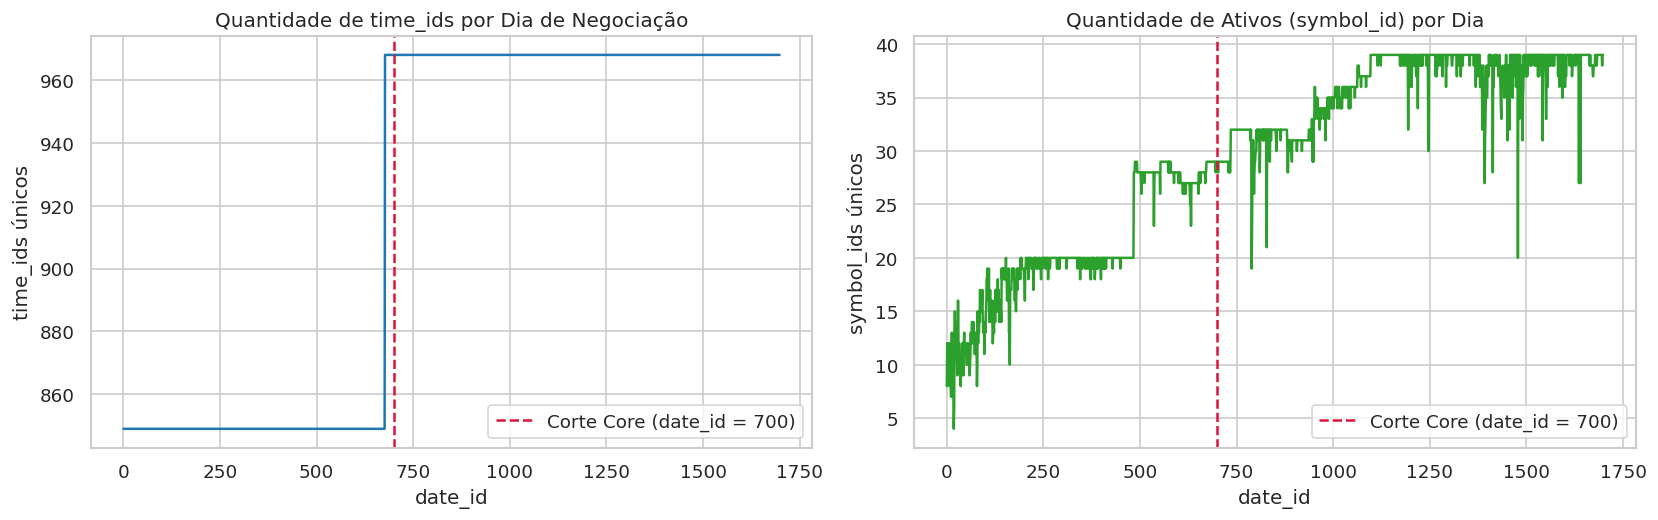

,Período,Dias,time_ids/dia (Mín-Máx),Registros
0,Anterior (date_id < 700),700,849 - 968,12362586
1,Estável (date_id >= 700),999,968 - 968,34764752


In [5]:
# Contagem de time_ids e symbol_ids únicos por dia
estabilidade = df_meta.groupby("date_id").agg(
    n_time_ids=("time_id", "nunique"),
    n_symbols=("symbol_id", "nunique"),
    n_rows=("time_id", "count")
).reset_index()
# n_time_ids: quantos instantes intradiários (time_id) distintos existiram naquele dia;
# n_symbols: quantos ativos (symbol_id) foram negociados naquele dia;
# n_rows: total de registros (linhas) daquele dia.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(estabilidade["date_id"], estabilidade["n_time_ids"], color="#1f77b4", lw=1.5)
axes[0].axvline(DATE_CUTOFF, color="crimson", linestyle="--", lw=1.5, label=f"Corte Core (date_id = {DATE_CUTOFF})")
axes[0].set_title("Quantidade de time_ids por Dia de Negociação")
axes[0].set_xlabel("date_id")
axes[0].set_ylabel("time_ids únicos")
axes[0].legend()

axes[1].plot(estabilidade["date_id"], estabilidade["n_symbols"], color="#2ca02c", lw=1.5)
axes[1].axvline(DATE_CUTOFF, color="crimson", linestyle="--", lw=1.5, label=f"Corte Core (date_id = {DATE_CUTOFF})")
axes[1].set_title("Quantidade de Ativos (symbol_id) por Dia")
axes[1].set_xlabel("date_id")
axes[1].set_ylabel("symbol_ids únicos")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_estabilidade_temporal.png"), dpi=200, bbox_inches="tight")
plt.show()

resumo_corte = pd.DataFrame([
    {
        "Período": f"Anterior (date_id < {DATE_CUTOFF})",
        "Dias": len(estabilidade[estabilidade["date_id"] < DATE_CUTOFF]),
        "time_ids/dia (Mín-Máx)": f"{estabilidade[estabilidade['date_id'] < DATE_CUTOFF]['n_time_ids'].min()} - {estabilidade[estabilidade['date_id'] < DATE_CUTOFF]['n_time_ids'].max()}",
        "Registros": int(estabilidade[estabilidade["date_id"] < DATE_CUTOFF]["n_rows"].sum()),
    },
    {
        "Período": f"Estável (date_id >= {DATE_CUTOFF})",
        "Dias": len(estabilidade[estabilidade["date_id"] >= DATE_CUTOFF]),
        "time_ids/dia (Mín-Máx)": f"{estabilidade[estabilidade['date_id'] >= DATE_CUTOFF]['n_time_ids'].min()} - {estabilidade[estabilidade['date_id'] >= DATE_CUTOFF]['n_time_ids'].max()}",
        "Registros": int(estabilidade[estabilidade["date_id"] >= DATE_CUTOFF]["n_rows"].sum()),
    }
])
display(resumo_corte)

### **Conclusão**

A análise da série histórica completa revela uma transição
  estrutural no mercado ao longo do tempo. No período inicial (date_id
  < 700), observa-se elevada variabilidade tanto na quantidade de
  instantes intradiários por pregão (n_time_ids variando de [849] a
  [968]]) quanto no universo de ativos negociados (symbol_id),
  caracterizando um cenário de forte domain shift e menor
  representatividade estrutural em relação ao regime recente.

  A partir de date_id >= 700, a granularidade intradiária estabiliza-
  se de forma consistente em 968 time_ids por dia (totalizando
  [999] dias e [34764752] registros), acompanhada por um
  conjunto de ativos mais uniforme. Essa evidência fundamenta três decisões centrais da arquitetura Core:

  1. **Redução de Domain Shift:** Descartar os pregões anteriores ao dia
  700 evita que a rede neural ajuste pesos sobre dinâmicas de mercado
  e tamanhos de pregão incompatíveis com o período de avaliação.
  1. **Padronização das Sequências Temporais (T = 968):** A constância de
  968 instantes diários viabiliza o treinamento com sequências de dia
  inteiro (e sub-janelas intradiárias T ∈ {64, 128, 256} no Bloco C)
  sem necessidade de padding excessivo ou truncamento irregular entre
  dias.
  1. **Eficiência Computacional:** A filtragem reduz significativamente o
  volume de dados em memória sem sacrificar a janela histórica
  relevante para a validação temporal (Time-Series CV com 2 folds e
  gap de 200 dias).

## 3. Distribuição do Alvo Principal (`responder_6`) e Pesos (`weight`)

Avaliamos a simetria, a presença de caudas pesadas (*outliers*) em `responder_6` (justificando o teste da **Huber Loss** no Bloco E) e a proporção de amostras com peso nulo (justificando `sample_weight`).

In [6]:
# Filtra para o período estável do Core
df_estavel = df_meta[df_meta["date_id"] >= DATE_CUTOFF].copy()
del df_meta
gc.collect()
y = df_estavel[TARGET_COL].dropna().values
w = df_estavel["weight"].dropna().values

stats_df = pd.DataFrame([
    {
        "Variável": TARGET_COL,
        "Média": np.mean(y),
        "Desvio Padrão": np.std(y),
        "Mínimo": np.min(y),
        "Mediana": np.median(y),
        "Máximo": np.max(y),
        "Assimetria (Skew)": skew(y),
        "Curtose (Excess)": kurtosis(y),
        "NaNs (%)": df_estavel[TARGET_COL].isna().mean() * 100
    },
    {
        "Variável": "weight",
        "Média": np.mean(w),
        "Desvio Padrão": np.std(w),
        "Mínimo": np.min(w),
        "Mediana": np.median(w),
        "Máximo": np.max(w),
        "Assimetria (Skew)": skew(w),
        "Curtose (Excess)": kurtosis(w),
        "NaNs (%)": df_estavel["weight"].isna().mean() * 100
    }
]).round(4)

display(stats_df)
print(f"[*] Amostras com weight == 0: {(w == 0).sum():,} ({(w == 0).mean()*100:.2f}%)")

,Variável,Média,Desvio Padrão,Mínimo,Mediana,Máximo,Assimetria (Skew),Curtose (Excess),NaNs (%)
0,responder_6,-0.0020,0.8704,-5.0000,-0.029,5.0000,0.5805,7.4108,0.0
1,weight,2.1103,1.1461,0.2688,1.844,10.2404,1.3512,2.4512,0.0


[*] Amostras com weight == 0: 0 (0.00%)


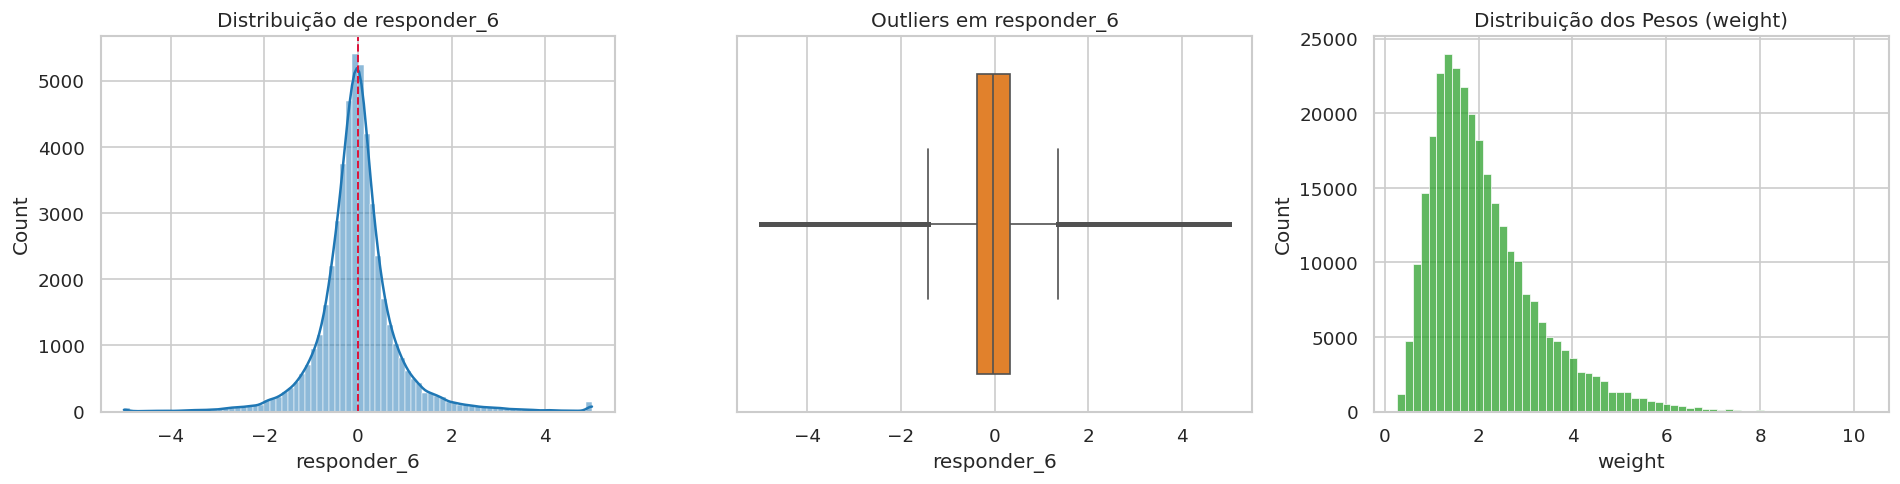

In [7]:
# Amostra de até 300k pontos para plotagem rápida (KDE em subamostra de 50k)
idx_plot = np.random.choice(len(y), size=min(300_000, len(y)), replace=False)
idx_kde = idx_plot[:min(50_000, len(idx_plot))]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.histplot(y[idx_kde], bins=80, kde=True, color="#1f77b4", ax=axes[0])
axes[0].axvline(0, color="crimson", linestyle="--", lw=1.2)
axes[0].set_title(f"Distribuição de {TARGET_COL}")
axes[0].set_xlabel(TARGET_COL)

sns.boxplot(x=y[idx_plot], color="#ff7f0e", ax=axes[1], fliersize=2)
axes[1].set_title(f"Outliers em {TARGET_COL}")
axes[1].set_xlabel(TARGET_COL)

sns.histplot(w[idx_plot], bins=60, color="#2ca02c", ax=axes[2])
axes[2].set_title("Distribuição dos Pesos (weight)")
axes[2].set_xlabel("weight")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_alvo_e_pesos.png"), dpi=200, bbox_inches="tight")
plt.show()

### **Conclusão** 

* **responder_6 (Alvo):** Apresenta 0% de NaNs, média praticamente nula
(-0.0020, mediana -0.0290) e desvio padrão de 0.8704, com valores
limitados em [-5.0, +5.0]. 
A curtose excessiva elevada (7.4108)
evidencia caudas pesadas (forte presença de outliers).
* **weight (Pesos):** Também possui 0% de NaNs e nenhuma amostra com
peso nulo após date_id >= 700 (mínimo 0.2688), mas exibe alta
dispersão assimétrica (0.2688 a 10.2404, média 2.1103) — uma
diferença de ~38× entre o menor e o maior peso.

Impacto nas decisões do projeto:

1. A média próxima de zero fundamenta a métrica oficial Zero-Mean
Weighted R².
2. A grande amplitude dos pesos torna indispensável o uso de sample_weight=weight no treinamento.
3. As caudas pesadas (curtose = 7.41) justificam o experimento de
ablação do Bloco E (Huber Loss vs. MSE) para avaliar maior robustez
a outliers.


## 4. Correlação entre Alvos (`responder_0` a `responder_8`)

Verifica a relação linear entre o alvo principal (`responder_6`) e os alvos auxiliares (`responder_7` e `responder_8`), fundamentando o experimento **Multi-Task (Bloco D)**.

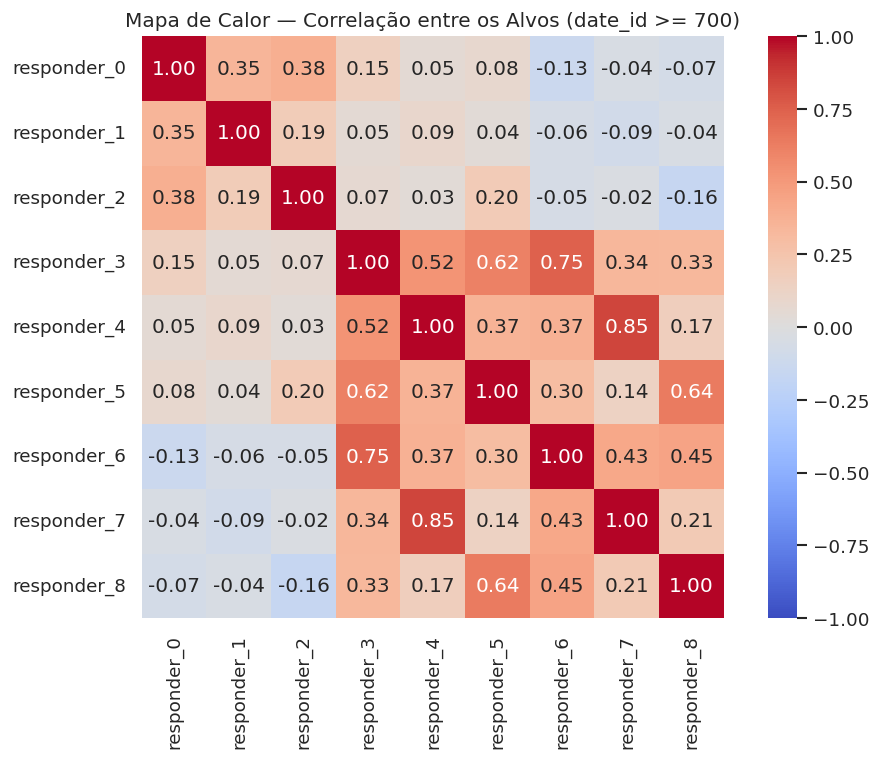

17182

In [8]:
# Amostra uniforme de até 1M de registros para evitar pico de RAM (float64) no .corr()
n_corr = min(1_000_000, len(df_estavel))
idx_corr = np.linspace(0, len(df_estavel) - 1, n_corr, dtype=int)
corr_resp = df_estavel.iloc[idx_corr][RESPONDER_COLS].corr()

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr_resp, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Mapa de Calor — Correlação entre os Alvos (date_id >= 700)")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_correlacao_responders.png"), dpi=200, bbox_inches="tight")
plt.show()

# Mantém apenas as colunas necessárias para a Seção 7 (volatilidade diária) e libera o resto da RAM
df_estavel = df_estavel[["date_id", TARGET_COL]].copy()
del y, w
gc.collect()

 ### **Conclusão**

O mapa de calor evidencia uma estrutura heterogênea entre os 9
*responders*: `responder_1` e `responder_2` apresentam correlação
praticamente nula com os demais, enquanto `responder_6` exibe
**correlação forte especificamente com `responder_3` (`r =
0.75`)** — além do par `responder_4`/`responder_7` (`r = 0.85`) e
correlações moderadas (`0.30 < r < 0.64`) entre os demais alvos.

**Impacto nas decisões do projeto:**
1. **Prevenção de *Negative Transfer*:** Descarta-se o uso de
todos os 9 alvos em conjunto, pois `responder_1` e `responder_2`
são estatisticamente desacoplados e competiriam pela capacidade da
rede sem beneficiar `responder_6`.
2. **Refinamento do Bloco D (*Multi-Task*):** Além do conjunto
`responder_6 + 7 + 8` (referência da literatura da competição), a
EDA revela **`responder_3` (`r = 0.75`)** como o alvo auxiliar
mais promissor para regularização multitarefa sobre o Core
*single-task*.

## 5. Radiografia de Valores Ausentes (`NaN`) nas 79 Features

Carregamos uma amostra estratificada ao longo do tempo (`date_id >= 700`, até 250.000 registros em `float32`) contendo todas as 79 *features* para mapear padrões de valores ausentes e correlações sem sobrecarregar a RAM.

In [ ]:
# Amostragem dos dados
AMOSTRA_TOTAL = 250_000
amostra_por_arq = max(1, AMOSTRA_TOTAL // max(1, len(arquivos_treino)))
cols_feat = ["date_id", "time_id", "symbol_id", TARGET_COL] + FEATURE_COLS

dfs_sample = []
for arq in arquivos_treino:
    part = pd.read_parquet(arq, columns=cols_feat)
    part = part[part["date_id"] >= DATE_CUTOFF]
    if len(part) > 0:
        if len(part) > amostra_por_arq:
            idx = np.linspace(0, len(part) - 1, amostra_por_arq, dtype=int)
            part = part.iloc[idx]
        for c in FEATURE_COLS + [TARGET_COL]:
            part[c] = part[c].astype("float32")
        dfs_sample.append(part)

df_sample = pd.concat(dfs_sample, ignore_index=True)
del dfs_sample
gc.collect()

print(f"[*] Amostra de features carregada: {df_sample.shape}")

[*] Amostra de features carregada: (150000, 83)


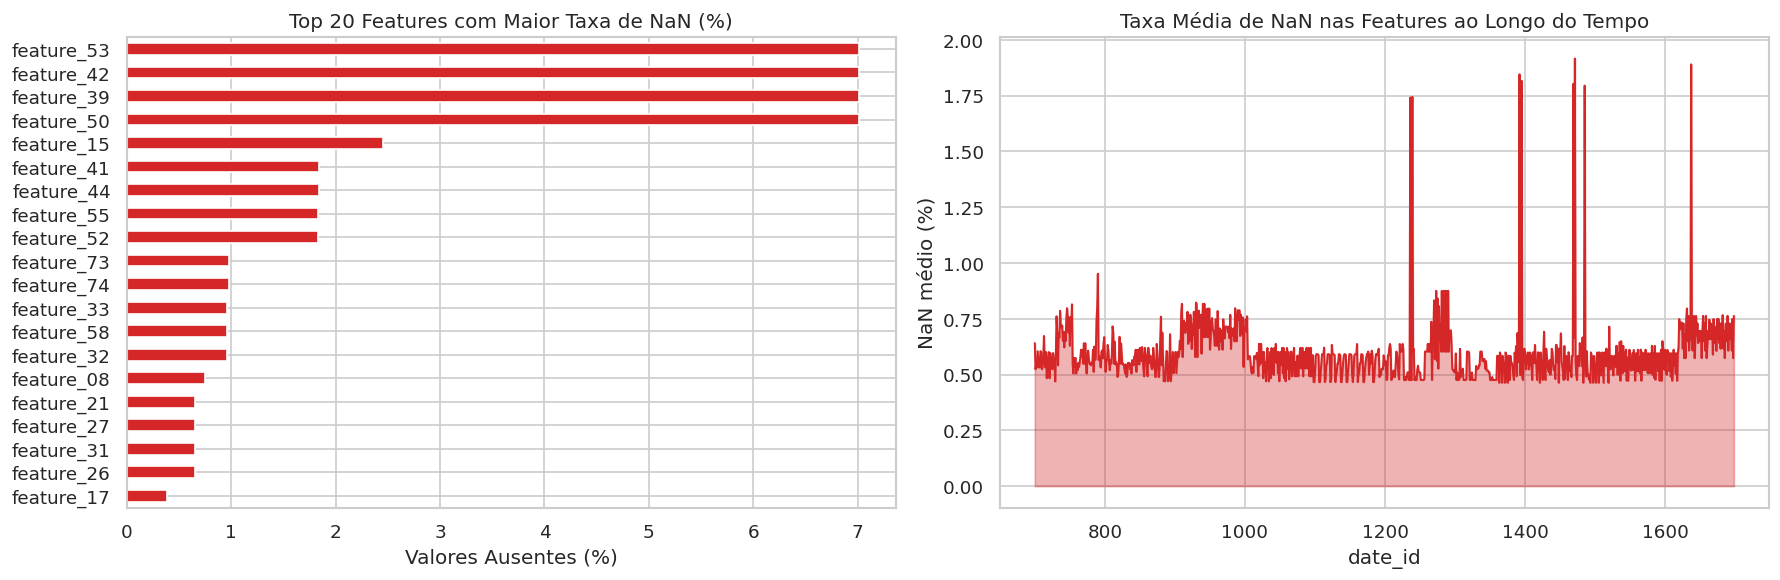

[*] Features com pelo menos 1 NaN: 31 de 79
[*] Taxa global de NaN na matriz de features: 0.60%


In [10]:
# Percentual de NaNs por feature e evolução por date_id
nan_por_feat = (df_sample[FEATURE_COLS].isna().mean() * 100).sort_values(ascending=False)
nan_por_dia = df_sample.groupby("date_id")[FEATURE_COLS].apply(lambda g: g.isna().mean().mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

nan_por_feat.head(20).sort_values().plot(kind="barh", color="#d62728", ax=axes[0])
axes[0].set_title("Top 20 Features com Maior Taxa de NaN (%)")
axes[0].set_xlabel("Valores Ausentes (%)")

axes[1].fill_between(nan_por_dia.index, nan_por_dia.values, color="#d62728", alpha=0.35)
axes[1].plot(nan_por_dia.index, nan_por_dia.values, color="#d62728", lw=1.2)
axes[1].set_title("Taxa Média de NaN nas Features ao Longo do Tempo")
axes[1].set_xlabel("date_id")
axes[1].set_ylabel("NaN médio (%)")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_valores_ausentes.png"), dpi=200, bbox_inches="tight")
plt.show()

print(f"[*] Features com pelo menos 1 NaN: {(nan_por_feat > 0).sum()} de {len(FEATURE_COLS)}")
print(f"[*] Taxa global de NaN na matriz de features: {df_sample[FEATURE_COLS].isna().mean().mean()*100:.2f}%")

### **Conclusão**

Embora o alvo (`responder_6`) e os pesos (`weight`) não possuam
valores ausentes, a radiografia das 79 *features* no período
estável (`date_id >= 700`, amostra de 150.000 registros) revela
que **31 de 79 variáveis (39,2%) apresentam valores `NaN`**, com
uma **taxa global de 0,60%** distribuída ao longo do tempo
(`date_id`). Esse padrão inviabiliza o descarte de linhas
(`dropna`), pois quebraria a continuidade das sequências
intradiárias, e exige tratamento explícito antes da entrada nas
redes recorrentes.

**Impacto nas decisões do projeto:**
1. **Imputação Neutra no Core (`NaN = 0.0`):** Como a taxa global
de ausências é baixa (`0,60%`), preencher nulos com `0.0` após o
`StandardScaler` (equivalente à média do treino) preserva o
comprimento das janelas sem distorcer a distribuição global das
*features*.
2. **Fundamentação do Bloco A (`Forward Fill`):** Como os `NaN`s
se concentram em um subconjunto específico de *features* ao longo
do tempo, o experimento de ablação testará se propagar a última
observação válida por ativo (`ffill` por `symbol_id`) melhora a
representação temporal frente à imputação neutra.

## 6. Correlação com `responder_6` e Colinearidade entre Features

Verificamos:
1. A baixa correlação linear individual com `responder_6` (justificando seleção não linear via Random Forest/XGBoost e modelos recorrentes).
2. Blocos de alta colinearidade entre variáveis (justificando a poda de ruído para Top 30–50 *features*).

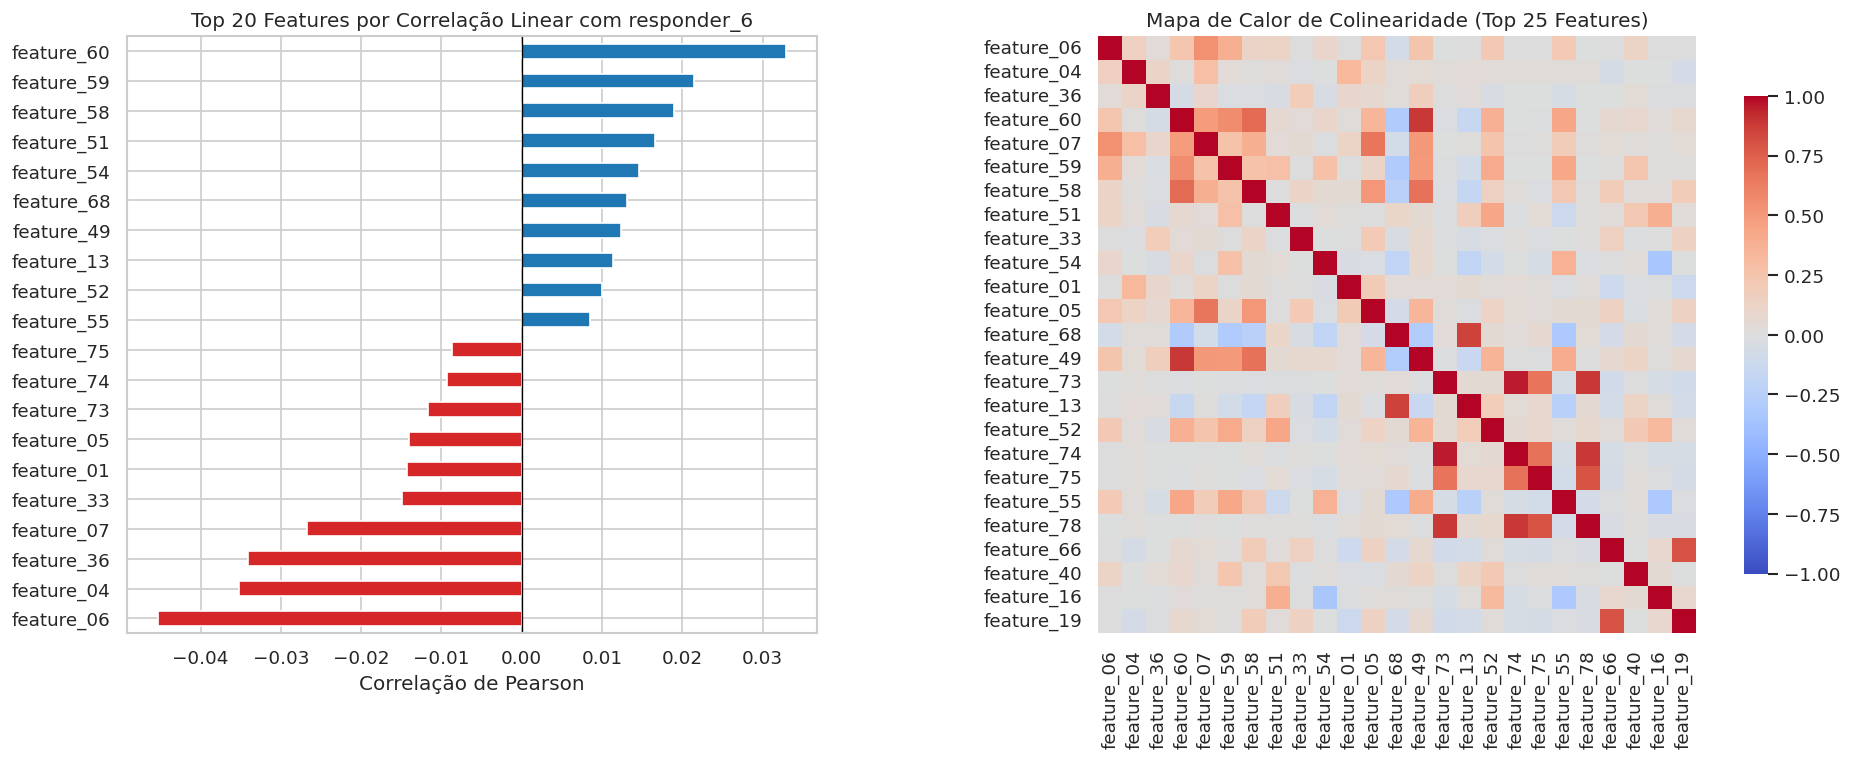

In [11]:
# Correlação de cada feature com o alvo principal
corr_alvo = df_sample[FEATURE_COLS].corrwith(df_sample[TARGET_COL]).dropna()
top25_feats = corr_alvo.abs().sort_values(ascending=False).head(25).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.4]})

# 1. Barras: Top 20 correlações com responder_6
top20 = corr_alvo.loc[top25_feats[:20]].sort_values()
cores = ["#1f77b4" if v >= 0 else "#d62728" for v in top20.values]
top20.plot(kind="barh", color=cores, ax=axes[0])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title(f"Top 20 Features por Correlação Linear com {TARGET_COL}")
axes[0].set_xlabel("Correlação de Pearson")

# 2. Mapa de calor de colinearidade entre as Top 25 features
corr_matrix_25 = df_sample[top25_feats].corr()
sns.heatmap(corr_matrix_25, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title("Mapa de Calor de Colinearidade (Top 25 Features)")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_correlacao_features.png"), dpi=200, bbox_inches="tight")
plt.show()

### **Conclusão**

A análise das correlações evidencia duas características centrais
do problema financeiro de alta frequência:

1. **Baixíssimo sinal linear isolado:** Mesmo as *features* mais
correlacionadas com `responder_6` apresentam coeficientes de
Pearson abaixo de `0,05` em módulo (destaque para `feature_06` com
`r ≈ -0.045` e `feature_60` com `r ≈ +0.033`), indicando que o
poder preditivo reside em interações não lineares e dependências
temporais.
2. **Blocos de multicolinearidade:** O mapa de calor revela grupos
de *features* fortemente redundantes entre si (como `{feature_73,
74, 75, 78}`, `{feature_60, 49, 58}`, `{feature_68, 13}` e
`{feature_66, 19}`).

**Impacto nas decisões do projeto:**
- **Seleção não linear e poda (79 → 40 *features*):** Justifica o
uso de `RandomForestRegressor` (em vez de filtro linear) no
`02_preparacao_core.ipynb` para reter os sinais mais informativos
e podar redundâncias.
- **Modelagem recorrente e Engenharia de Features (Bloco B):**
Fundamenta a necessidade de arquiteturas profundas temporais
(`GRU`/`LSTM`/`CNN-LSTM`/`Attention`) e da criação de interações e
agregados (ex.: interações envolvendo `feature_06`) para
amplificar a baixa relação sinal-ruído.

## 7. Validação Estatística: Estacionariedade (ADF) e *Regime Shift*

- **Teste ADF (*Augmented Dickey-Fuller*):** Testa a hipótese nula ($H_0$) de existência de raiz unitária (série não estacionária). Valores $p < 0.05$ indicam estacionariedade.
- **Mudança de Regime (*Regime Shift*):** Evolução da volatilidade diária de `responder_6` com marcação das janelas de Treino, Validação, **Gap (200 dias)** e Teste Privado.

In [12]:
# 7.1 Teste de Hipótese ADF (Augmented Dickey-Fuller) — Verificação de Estacionariedade
# H0 (Hipótese Nula): A série possui raiz unitária (NÃO é estacionária — ex.: tem tendência/passeio aleatório).
# H1 (Hipótese Alternativa): A série é estacionária na média (oscila em torno de um nível constante).
# Regra de decisão (α = 0.05): se p-valor < 0.05 (e Estatística ADF < Valor Crítico 5%), rejeitamos H0 -> Estacionária.

# 1. Seleciona o ativo (symbol_id) com mais registros na amostra para formar uma série temporal longa e contínua
top_symbol = df_sample["symbol_id"].value_counts().idxmax()

# 2. Agrega o alvo principal e as 5 features mais correlacionadas pela média diária (1 valor por date_id),
#    removendo dias com NaN para evitar erro no cálculo do teste ADF
df_sym = (
    df_sample[df_sample["symbol_id"] == top_symbol]
    .groupby("date_id")[[TARGET_COL] + top25_feats[:5]]
    .mean()
    .dropna()
)

adf_rows = []
for col in [TARGET_COL] + top25_feats[:5]:
    serie = df_sym[col].values
    # Exige mínimo de observações para o teste estatístico ter validade
    if len(serie) > 20:
        # autolag="AIC" escolhe automaticamente o número ótimo de defasagens (lags) do teste via Critério de Akaike
        stat, pval, _, _, crit, _ = adfuller(serie, autolag="AIC")
        adf_rows.append({
            "Série (symbol_id=" + str(top_symbol) + ")": col,
            "Estatística ADF": round(stat, 4),   # Quanto mais negativo, mais forte a evidência contra H0
            "p-valor": round(pval, 6),           # Probabilidade de observar essa estatística se H0 fosse verdadeira
            "Crítico (5%)": round(crit["5%"], 4),# Limiar crítico para nível de significância α = 0.05
            "Resultado (α=0.05)": "Estacionária" if pval < 0.05 else "Não Estacionária"
        })

display(pd.DataFrame(adf_rows))

/tmp/ipykernel_23720/2948453224.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pval, _, _, crit, _ = adfuller(serie, autolag="AIC")
/tmp/ipykernel_23720/2948453224.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pval, _, _, crit, _ = adfuller(serie, autolag="AIC")
/tmp/ipykernel_23720/2948453224.py:14: FutureWarning: adfuller currently returns a pla

,Série (symbol_id=36),Estatística ADF,p-valor,Crítico (5%),Resultado (α=0.05)
0,responder_6,-30.6542,0.0,-2.8647,Estacionária
1,feature_06,-12.6132,0.0,-2.8647,Estacionária
2,feature_04,-20.7309,0.0,-2.8647,Estacionária
3,feature_36,-15.9452,0.0,-2.8647,Estacionária
4,feature_60,-20.1901,0.0,-2.8647,Estacionária
5,feature_07,-12.1225,0.0,-2.8647,Estacionária


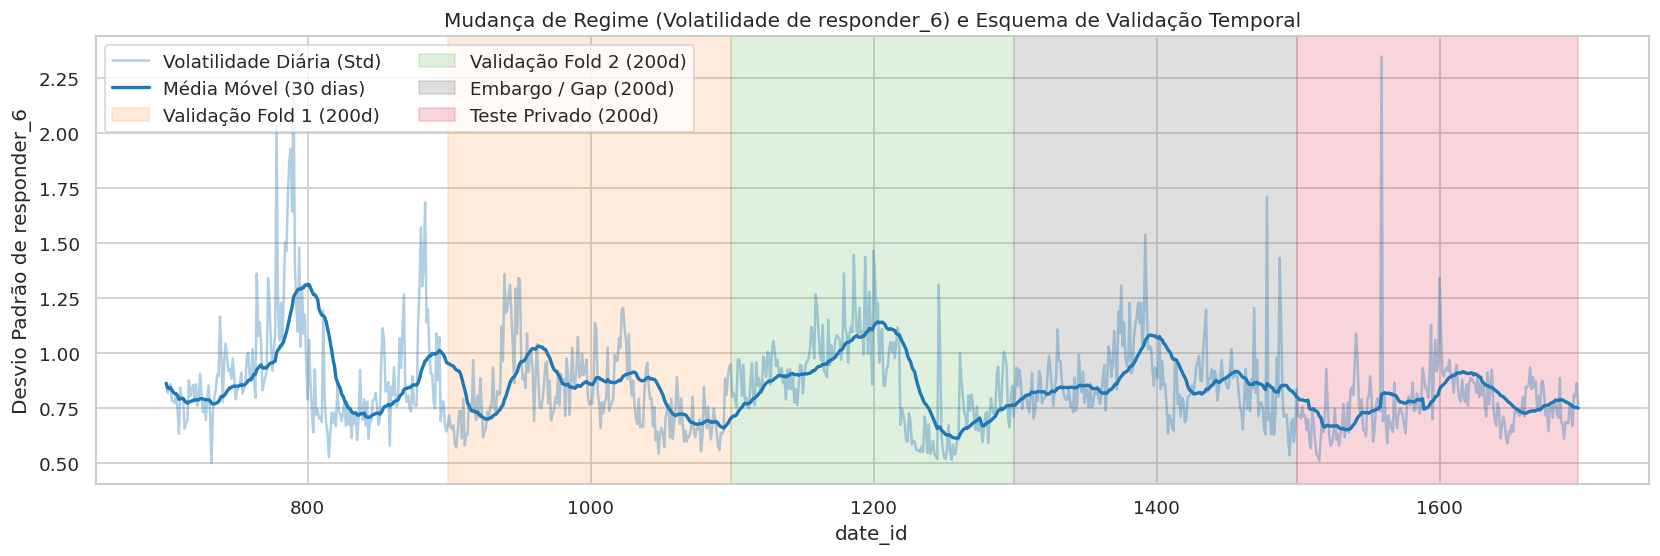

In [13]:
# 7.2 Volatilidade diária de responder_6 e visualização dos blocos do CV Temporal + Gap
vol_diaria = df_estavel.groupby("date_id")[TARGET_COL].std().sort_index()
vol_rolling = vol_diaria.rolling(window=30, min_periods=1).mean()

dias = vol_diaria.index.values

plt.figure(figsize=(14, 4.8))
plt.plot(vol_diaria.index, vol_diaria.values, color="#1f77b4", alpha=0.35, label="Volatilidade Diária (Std)")
plt.plot(vol_rolling.index, vol_rolling.values, color="#1f77b4", lw=2, label="Média Móvel (30 dias)")

if len(dias) > 800:
    test_ini = dias[-200]
    gap_ini = dias[-400]
    val2_ini = dias[-600]
    val1_ini = dias[-800]

    plt.axvspan(val1_ini, val2_ini, color="#ff7f0e", alpha=0.15, label="Validação Fold 1 (200d)")
    plt.axvspan(val2_ini, gap_ini, color="#2ca02c", alpha=0.15, label="Validação Fold 2 (200d)")
    plt.axvspan(gap_ini, test_ini, color="gray", alpha=0.25, label="Embargo / Gap (200d)")
    plt.axvspan(test_ini, dias[-1], color="crimson", alpha=0.18, label="Teste Privado (200d)")
else:
    print(f"[!] Aviso: apenas {len(dias)} dias disponíveis após corte; marcação dos blocos de 200d omitida.")

plt.title(f"Mudança de Regime (Volatilidade de {TARGET_COL}) e Esquema de Validação Temporal")
plt.xlabel("date_id")
plt.ylabel(f"Desvio Padrão de {TARGET_COL}")
plt.legend(loc="upper left", ncol=2, frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, f"{PREFIXO}_regime_shift.png"), dpi=200, bbox_inches="tight")
plt.show()

### **Conclusão**

Os testes estatísticos revelam um comportamento típico de séries
financeiras de alta frequência — **estacionariedade na média, mas
não estacionariedade na variância**:

1. **Estacionariedade na Média (Teste ADF — `symbol_id = 36`):**
Tanto `responder_6` (`ADF = -30.6542`) quanto as cinco *features*
mais correlacionadas (`ADF` entre `-12.1225` e `-20.7309`, frente
ao valor crítico de `-2.8647` a 5%) rejeitaram a hipótese de raiz
unitária com **`p-valor = 0.0`**. Assim, não há tendência
determinística/estocástica que exija diferenciação prévia das
séries.
2. **Mudanças de Regime (*Regime Shifts* na Volatilidade):** A
volatilidade diária de `responder_6` exibe forte *volatility
clustering*, com a média móvel de 30 dias alternando entre regimes
de baixa (`std ≈ 0.60–0.70`) e alta turbulência (`std ≈
1.15–1.30`), além de choques extremos acima de `2.0` no início do
período e `2.35` dentro do Teste Privado (`date_id ≈ 1560`).

**Impacto nas decisões do projeto:**
- **Dispensa de diferenciação:** A estacionariedade confirmada
pelo ADF permite aplicar apenas a padronização (`StandardScaler`
no treino) antes da modelagem recorrente.
- **Validação Temporal Estrita com *Gap* de 200 dias:** A presença
de *regime shifts* torna o *split* aleatório inválido por
vazamento temporal e fundamenta o protocolo de **Time-Series CV (2
folds de 200 dias) + Embargo de 200 dias**, avaliando a robustez
das arquiteturas frente a regimes de volatilidade não vistos no
treinamento.

## 8. Síntese das Evidências (Conexão com o Core)

| Achado da EDA | Figura Gerada | Decisão Justificada no Projeto |
| :--- | :--- | :--- |
| Estabilização em 968 `time_id`s/dia a partir do dia 700 | `eda_estabilidade_temporal.png` | Filtro `date_id >= 700` no Core e `T = 968` no Bloco C |
| Média de `responder_6` próxima de 0, caudas pesadas e pesos variados | `eda_alvo_e_pesos.png` | Métrica *Zero-Mean Weighted $R^2$*, `sample_weight` e teste de *Huber Loss* (Bloco E) |
| Correlação estrutural entre `responder_6`, `7` e `8` | `eda_correlacao_responders.png` | Experimento *Multi-Task Learning* (Bloco D) |
| Presença relevante de `NaN`s distribuídos no tempo | `eda_valores_ausentes.png` | Imputação neutra (`NaN = 0`) no Core + ablação `ffill` (Bloco A) |
| Baixa correlação linear individual e colinearidade entre *features* | `eda_correlacao_features.png` | Poda para Top 30–50 via Random Forest/XGBoost no treino |
| Flutuações de volatilidade (*regime shift*) ao longo dos dias | `eda_regime_shift.png` | Proibição de split aleatório e validação temporal com *gap* de 200 dias |